# 1. Introduction

This project covers an analysis of the 2024 Stack Overflow Developer Survey dataset. It was completed as part of the IBM Data Analysis Professional Certificate.

In this project, we will use techniques such as data cleaning, exploratory data analysis, and data visualisation to manipulate and investigate the data.

Tools used include Python, Pandas, Matplotlib, Numpy, Seaborn, and Scipy.

Key questions:
- What demographics do respondents represent? (e.g.: age)
- What programming languages are most popular among respondents?
- What sort of work is most prevalent among respondents? (i.e.: remote, hybrid, in-person)
- What is the distribution of salaries among respondents?

# 2. Data Loading

The first step in the process is to load the dataset into a Pandas dataframe so that it can be cleaned and analysed.

In [46]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import scipy

# Load the dataset directly from the URL
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"

# Load the data into a Pandas dataframe
df = pd.read_csv(file_path)

In [47]:
# Ensure data has been loaded correctly
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


In [48]:
# Investigate the size of the dataset
df.shape

(65457, 114)

In [91]:
# Set visual style of graphs
sns.set_theme(style='whitegrid', palette='deep')

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['figure.dpi'] = 120

plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.titleweight'] = 'bold'

plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# 3. Data Cleaning and Preparation

The data then needs to be prepared and cleaned to account for any inconsistencies, duplicate or missing values, outliers, etc. in the data.

In [50]:
# Investigate the data types of columns in the dataset to ensure that they are appropriate
print(df.dtypes)

ResponseId               int64
MainBranch                 str
Age                        str
Employment                 str
RemoteWork                 str
                        ...   
JobSatPoints_11        float64
SurveyLength               str
SurveyEase                 str
ConvertedCompYearly    float64
JobSat                 float64
Length: 114, dtype: object


The datatype of the Age column is currently set to "string". If we want to do numerical analysis on this column, then it should be changed to a numeric value. Currently, the Age column contains values like "Under 18 years old", or "18-24 years old". We can map these values to integers and create a new column for analysis.

In [51]:
age_mapping = {
    "Under 18 years old": 17,
    "18-24 years old": 21,
    "25-34 years old": 30,
    "35-44 years old": 40,
    "45-54 years old": 50,
    "55-64 years old": 60,
    "65 years or older": 65,
    "Prefer not to say": np.nan
}

# Create a new numeric Age column
df['Age_numeric'] = df['Age'].map(age_mapping)

Next, we can investigate the dataset to determine if there are any duplicate rows.

In [52]:
# Count the number of duplicate rows in the dataset
print("There are", df.duplicated().sum(), "duplicate rows in the dataset")

There are 20 duplicate rows in the dataset


In [53]:
# Display the first few duplicate rows to understand their structure
df[df.duplicated()].head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat,Age_numeric
65437,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.0
65438,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,40.0
65439,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN,50.0
65440,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN,21.0
65441,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN,21.0


We can investigate duplicate response patterns to determine how to identify duplicate rows.

In [54]:
# Identify duplicate response pattens based on the MainBranch, Employment, and RemoteWork columns
pattern_cols = ['MainBranch', 'Employment', 'RemoteWork']
groups = df.groupby(pattern_cols)
duplicate_patterns = groups.filter(lambda x: len(x) > 1)
other_cols = [c for c in df.columns if c not in pattern_cols]
variation = (duplicate_patterns.groupby(pattern_cols)[other_cols].nunique())
consistency = (variation == 1).mean().sort_values(ascending = False)
print(consistency)

Check                    1.000000
ICorPM                   0.304075
AIThreat                 0.275862
SOAccount                0.266458
AINextLess integrated    0.238245
                           ...   
YearsCodePro             0.025078
TechEndorse              0.025078
BuyNewTool               0.021944
CodingActivities         0.003135
ResponseId               0.000000
Length: 112, dtype: float64


The column Check has a consistency score of 1 indicating that every qualifying group has the same Check value. This column should be investigated and potentially removed from the dataset.

In [55]:
# Investigate the Check column
print(df['Check'].value_counts(dropna = False))
print("There are",df['Check'].nunique(dropna = False), "unique values in the Check column")

Check
Apples    65457
Name: count, dtype: int64
There are 1 unique values in the Check column


The Check column only contains the value "Apples" and so is not useful for analysis and can be removed from the dataset.

In [56]:
# Remove the Check column
df = df.drop(columns = ['Check'], errors = 'ignore')

Now, we can check if our chosen pattern columns are appropriate for identifying unique survey records.

In [57]:
# Count repeated combinations of the three pattern columns
print("Total rows:", len(df))
print(
    "Rows with shared patterns:",
    df.duplicated(subset=pattern_cols, keep=False).sum()
)

Total rows: 65457
Rows with shared patterns: 65290


Most rows belong to a group sharing the same answers to the columns MainBranch, Employment, and RemoteWork indicating that these columns are unsuitable for identifying unique survey records.

A more suitable column is the ResponseId column:

In [58]:
# Check whether ResponseId is unique
print("Total rows:", len(df))
print("Unique response IDs:", df['ResponseId'].nunique())
print("Missing response IDs:", df['ResponseId'].isna().sum())

# Count exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Identify repeated values in ResponseId
repeated_ids = df[
    df.duplicated(subset=['ResponseId'], keep=False)
].sort_values('ResponseId')

print("Rows with repeated IDs:", len(repeated_ids))
print("Number of repeated IDs:", repeated_ids['ResponseId'].nunique())

Total rows: 65457
Unique response IDs: 65437
Missing response IDs: 0
Exact duplicate rows: 20
Rows with repeated IDs: 40
Number of repeated IDs: 20


The column ResponseId seems to correspond to exact duplicate entries in the survey, but this is worth double-checking.

In [59]:
# Double-check all duplicate ResponseId entries are exact duplicates
duplicate_id_check = (
    repeated_ids.groupby('ResponseId')
    .apply(lambda group: group.drop(columns = 'ResponseId', errors = 'ignore')
          .nunique().max() == 1)
)

# Check whether duplicate_id_check contains any values of False indicating that there are non-duplicate values
print("All repeated-ID groups are identical:",
      duplicate_id_check.all())

# Check how many groups contain differing answers
print("Repeated-ID groups with differing answers:",
      (~duplicate_id_check).sum())

All repeated-ID groups are identical: True
Repeated-ID groups with differing answers: 0


Now that the duplicate entries have been identified, we can safely remove them from the dataframe.

In [60]:
# Remove duplicate rows
df = df.drop_duplicates()

print("Rows after cleaning:", len(df))
print("Unique response IDs:", df['ResponseId'].nunique())
print("Exact duplicate rows:", df.duplicated().sum())

Rows after cleaning: 65437
Unique response IDs: 65437
Exact duplicate rows: 0


Next, identify missing values in the dataset.

In [61]:
# Calculate the proportion of values that are missing from each column
percentage_missing_values = (df.isnull().sum().sort_values(ascending = False)/len(df))*100
print(percentage_missing_values)

AINextMuch less integrated    98.245641
AINextLess integrated         96.401119
AINextNo change               80.900714
AINextMuch more integrated    79.464217
EmbeddedAdmired               74.428840
                                ...    
Age_numeric                    0.492076
MainBranch                     0.000000
ResponseId                     0.000000
Employment                     0.000000
Age                            0.000000
Length: 114, dtype: float64


Missing values can be filled in using appropriate values for the column, such as its mean, mode, median, etc., or, as may be more appropriate particularly for columns with a large proportion of missing values, simply removed when analysing specific columns.

In [62]:
important_columns = ['EdLevel', 'RemoteWork', 'Age', 'Country',
                     'CodingActivities', 'ConvertedCompYearly'
                    ]
print(percentage_missing_values[important_columns].sort_values())

Age                     0.000000
EdLevel                 7.110656
Country                 9.943916
RemoteWork             16.246160
CodingActivities       16.765744
ConvertedCompYearly    64.186928
dtype: float64


We can impute missing values in EdLevel and RemoteWork with the mode.

In [63]:
print("Before imputation:")
print(" EdLevel missing value count:", df['EdLevel'].isnull().sum())
print(" RemoteWork missing value count:", df['RemoteWork'].isnull().sum())

# Impute the empty rows in the columns RemoteWork and EdLevel with the most frequent value
for column in ['EdLevel', 'RemoteWork']:
    df[column] = df[column].fillna(df[column].mode()[0])

print("After imputation:")
print(" EdLevel missing value count:", df['EdLevel'].isnull().sum())
print(" RemoteWork missing value count:", df['RemoteWork'].isnull().sum())

Before imputation:
 EdLevel missing value count: 4653
 RemoteWork missing value count: 10631
After imputation:
 EdLevel missing value count: 0
 RemoteWork missing value count: 0


Certain columns have no missing values and so are likely ready for analysis. Columns like ConvertedCompYearly have over half of the values missing and so imputing a value into these columns would heavily skew the data and disrupt the analysis. We can instead create a separate dataframe for specific salary analysis and drop the missing values from that data.

In [64]:
salary_df = df.dropna(subset = ['ConvertedCompYearly']).copy()

# 4. Exploratory Data Analysis and Visualisations

Now that the data has been prepared, it is ready for some exploratory analysis.

## 4.1 Respondent Demographics

Let's take a look at what countries respondents came from.

In [65]:
print("Number of unique countries in survey:",len(df['Country'].unique()))

Number of unique countries in survey: 186


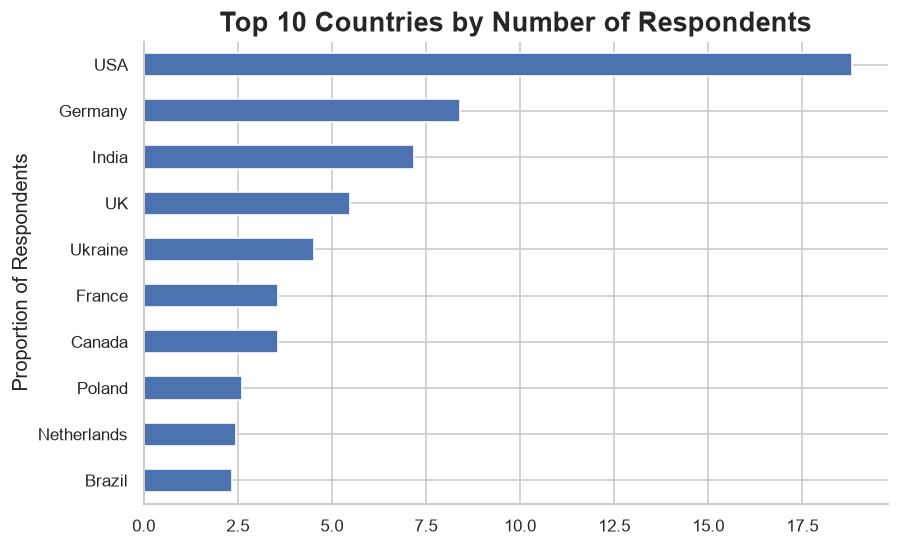

In [105]:
#Calculate top 10 most common countries
top_countries = df['Country'].value_counts(normalize = True).head(10).sort_values(ascending = True)*100

# Rename long country names
top_countries = top_countries.rename(index = {
    "United States of America" : "USA",
    "United Kingdom of Great Britain and Northern Ireland" : "UK"
})

# Plot a bar chart
top_countries.plot(kind = 'barh')
plt.title("Top 10 Countries by Number of Respondents")
plt.ylabel("Proportion of Respondents")
plt.show()

The USA is the country that the largest number of respondents came from, representing approximately 19% of the total number of respondents.

Let's also look at the mean age of developers.

In [67]:
# Calculate the mean age
print("Mean age of developers surveyed:", f'{df['Age_numeric'].mean():.{2}f}')

Mean age of developers surveyed: 33.35


The mean age of respondents was found to be just over 33 years old.

## 4.2 Salary Analysis

Now let's have a look at salary among respondents. We can use the salary dataframe that we prepared earlier. For analysis purposes, it is often useful to normalise values. We can normalise ConvertedCompYearly using Min-Max Scaling, which scales values to fit within the range 0-1.

In [69]:
# Calculate min-max scaling
salary_df['ConvertedCompYearly_MinMax'] = (
    (salary_df['ConvertedCompYearly'] - salary_df['ConvertedCompYearly'].min()) /
    (salary_df['ConvertedCompYearly'].max() - salary_df['ConvertedCompYearly'].min())
)
salary_df['ConvertedCompYearly_MinMax'].head()

72     0.000450
374    0.001850
379    0.005616
385    0.003303
389    0.006766
Name: ConvertedCompYearly_MinMax, dtype: float64

We can also apply Z-score Normalisation to ConvertedCompYearly, which transforms values so that they have a mean of 0 and a standard deviation of 1.

In [70]:
# Calculate Z-score
salary_df['ConvertedCompYearly_Z'] = (
    (salary_df['ConvertedCompYearly'] - salary_df['ConvertedCompYearly'].mean()) /
    salary_df['ConvertedCompYearly'].std()
)
salary_df['ConvertedCompYearly_Z'].head()

72    -0.422117
374   -0.300290
379    0.027521
385   -0.173767
389    0.127678
Name: ConvertedCompYearly_Z, dtype: float64

We can plot these values to investigate salary distribution. Note that the normalisation methods used do not affect the shape of the distribution.

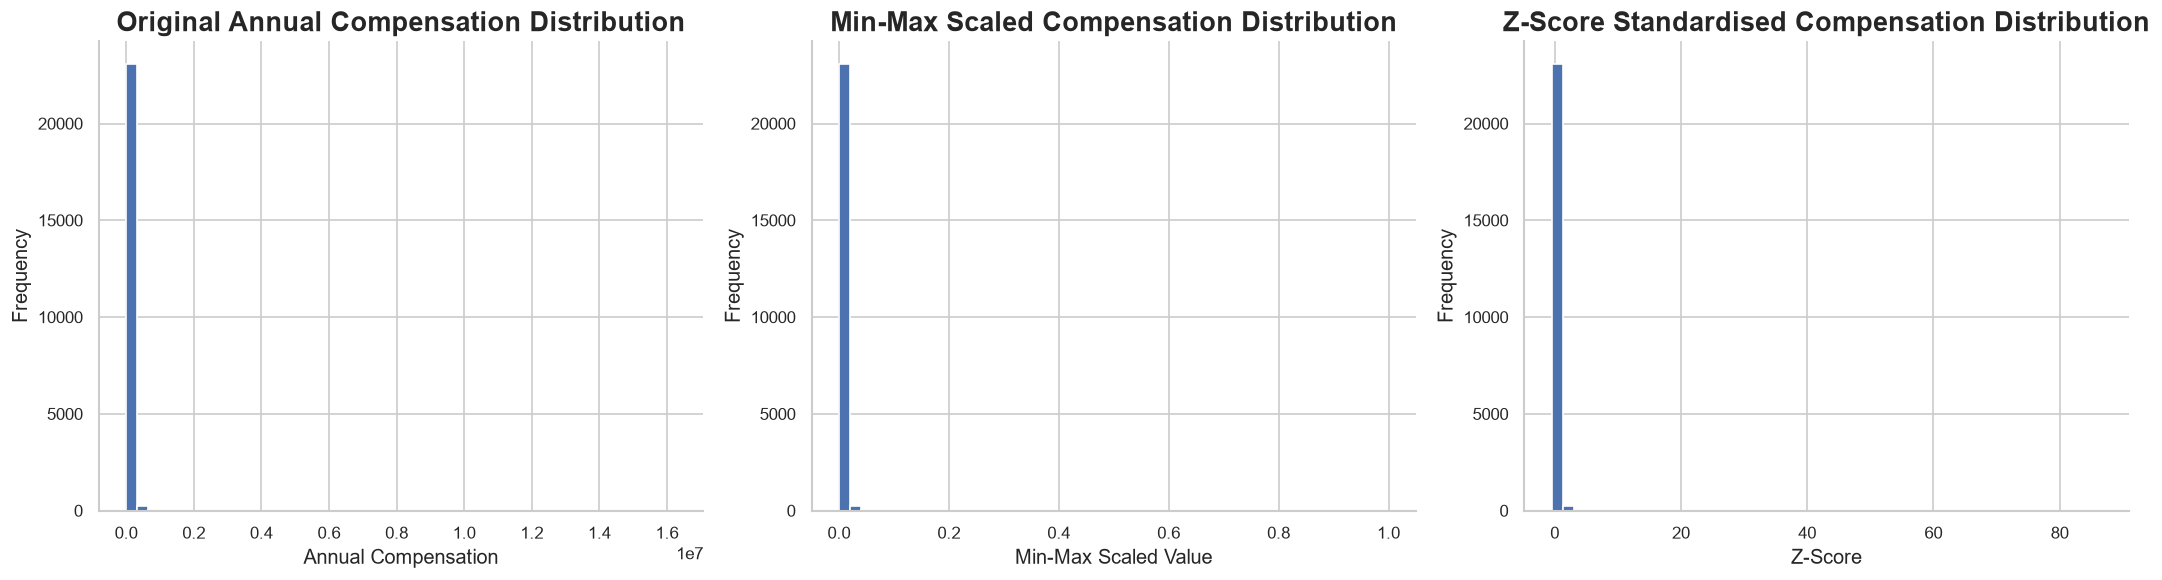

In [93]:
fig, axs = plt.subplots(1, 3, figsize = (18, 5))

# Plot ConvertedCompYearly
axs[0].hist(salary_df['ConvertedCompYearly'], bins = 50)
axs[0].set_title("Original Annual Compensation Distribution")
axs[0].set_xlabel("Annual Compensation")

# Plot min-max scaling
axs[1].hist(salary_df['ConvertedCompYearly_MinMax'], bins = 50)
axs[1].set_title("Min-Max Scaled Compensation Distribution")
axs[1].set_xlabel("Min-Max Scaled Value")

# Plot Z-score
axs[2].hist(salary_df['ConvertedCompYearly_Z'], bins = 50)
axs[2].set_title("Z-Score Standardised Compensation Distribution")
axs[2].set_xlabel("Z-Score")

for ax in axs:
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In these graphs, it is apparent that the data is being skewed by several extremely large values of salary, which makes observing any detail in the lower-salary range impossible.

We can investigate the number of extremely large values in the data.

In [72]:
salary_df['ConvertedCompYearly'].value_counts().sort_index(ascending = False).head()

ConvertedCompYearly
16256603.0    1
13818022.0    1
9000000.0     1
6340564.0     1
4936778.0     1
Name: count, dtype: int64

We can also investigate these using a box plot.

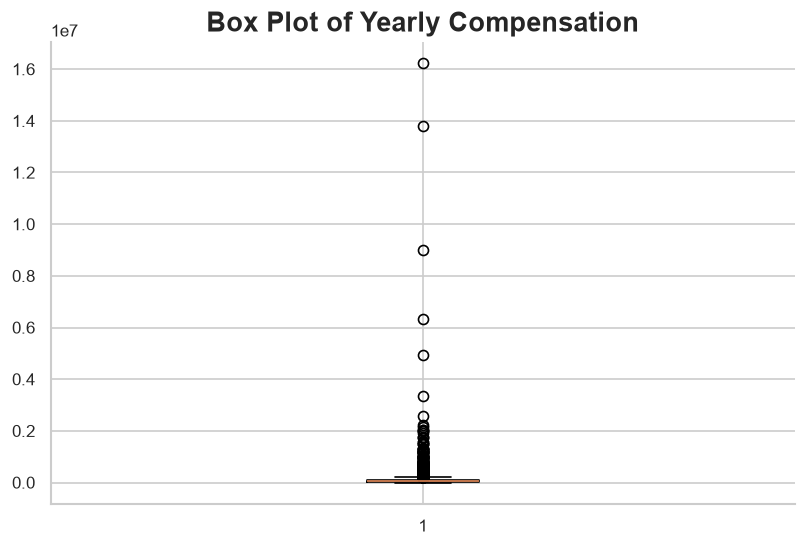

In [95]:
# Plot a box plot
plt.boxplot(salary_df['ConvertedCompYearly'])
plt.title('Box Plot of Yearly Compensation')

plt.show()

The data is clearly skewed by outliers.

We can identify outliers using several methods.

We can investigate values that lie outside of 3 standard deviations from the mean.

In [74]:
comp_stats = salary_df['ConvertedCompYearly'].describe()

threshold = comp_stats['mean'] + (3 * comp_stats['std'])

high_comp = salary_df[salary_df['ConvertedCompYearly'] > threshold]
print('Number of extreme compensation values:', len(high_comp))

Number of extreme compensation values: 89


We can also calculate the number of values in the top 1% of earners.

In [75]:
comp_01 = salary_df['ConvertedCompYearly'][salary_df['ConvertedCompYearly'] >
    salary_df['ConvertedCompYearly'].quantile(0.99)]

print('Number of values in top 1%:', len(comp_01))

Number of values in top 1%: 235


We can also use the IQR method to identify outliers.

In [76]:
IQR = comp_stats['75%'] - comp_stats['25%']
lower_bound = comp_stats['25%'] - (1.5 * IQR)
upper_bound = comp_stats['75%'] + (1.5 * IQR)

outliers = salary_df[(salary_df['ConvertedCompYearly'] < lower_bound) | (salary_df['ConvertedCompYearly'] > upper_bound)]

print('Number of outliers:', len(outliers))

Number of outliers: 978


Let's use the IQR method as the data is heavily right-skewed and IQR is less sensitive to extreme values than using the mean and standard deviation.

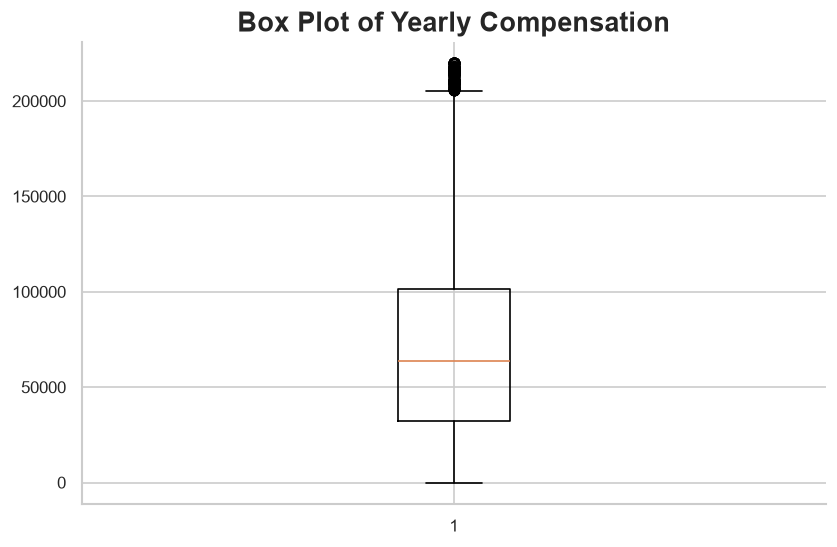

In [77]:
# Filter data
df_clean = salary_df[(salary_df['ConvertedCompYearly'] > lower_bound) & (salary_df['ConvertedCompYearly'] < upper_bound)]

# Plot a box plot
plt.boxplot(df_clean['ConvertedCompYearly'])
plt.title('Box Plot of Yearly Compensation')

plt.show()

This boxplot with outliers removed is much clearer.

We can also see the general distribution of the data much more clearly with outliers removed.

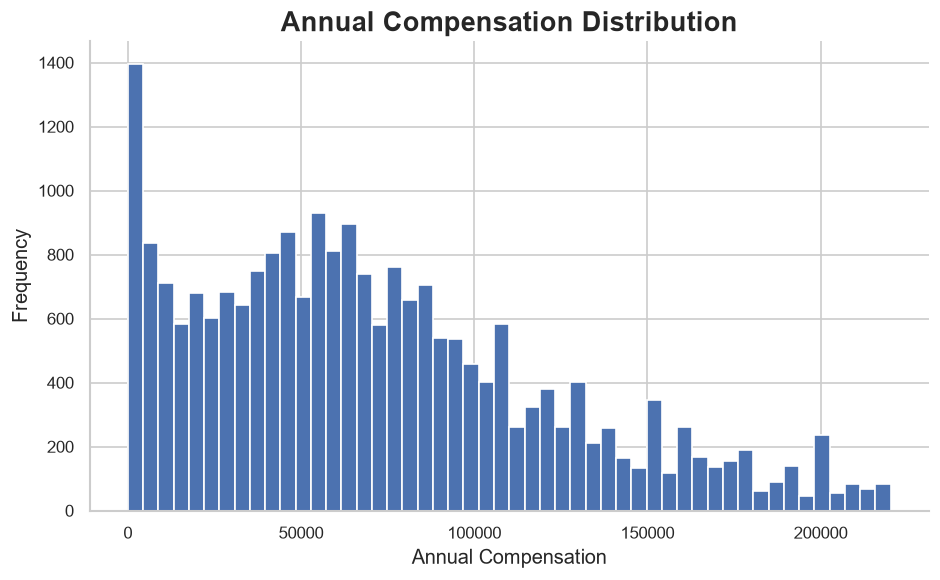

In [96]:
plt.hist(df_clean['ConvertedCompYearly'], bins = 50)
plt.title("Annual Compensation Distribution")
plt.xlabel("Annual Compensation")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Now let's investigate mean compensation for the top 10 most common countries in the survey.

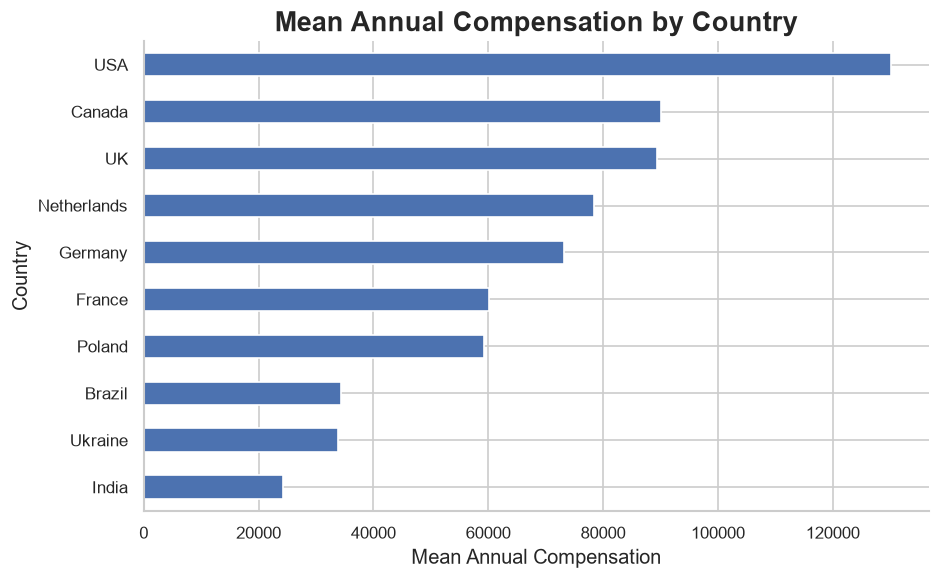

In [97]:

country_comp = (df_clean.groupby('Country')['ConvertedCompYearly']
                .agg(['mean', 'median', 'count'])
                .sort_values('mean', ascending = False)
               )

top_countries = df['Country'].value_counts().head(10).index

plot_data = country_comp.loc[top_countries].sort_values('mean')
plot_data = plot_data.rename(index = {
    'United States of America': 'USA',
    'United Kingdom of Great Britain and Northern Ireland': 'UK'
})

plot_data['mean'].plot(kind='barh')

plt.title('Mean Annual Compensation by Country')
plt.xlabel('Mean Annual Compensation')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

The USA was found to have the top mean annual compensation out of the top 10 countries most common to respondents. The top 10 countries were used as there were some countries with only one or two respondents which is not enough to be a reliable representation of that country.

## 4.3 Job Satisfaction Investigation

We can investigate how the amount of professional coding experience affects job satisfaction using a bar chart.

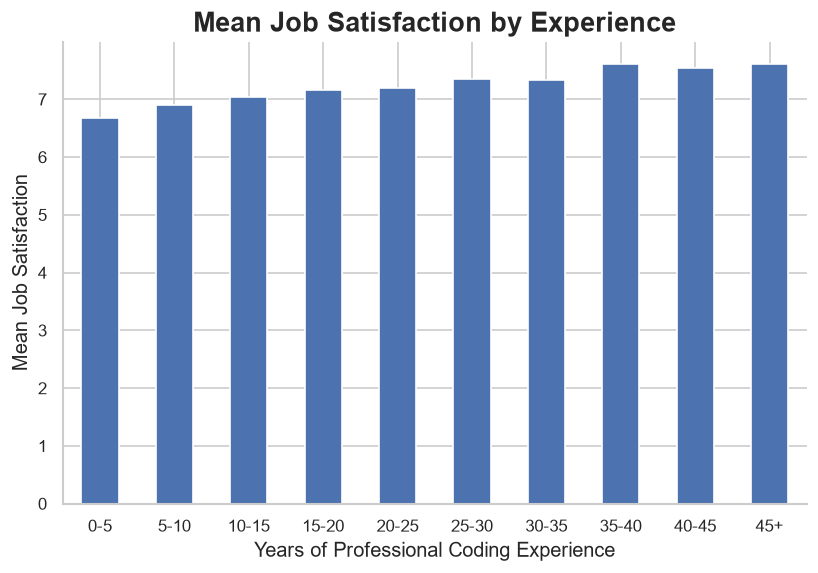

In [98]:
# Convert strings in YearsCodePro to numeric values for use in analysis
df['YearsCodePro'] = df['YearsCodePro'].replace(
    {'Less than 1 year' : 0.5,
     'More than 50 years' : 51})
df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'])

# Sort YearsCodePro into bins 
df['ExperienceRange'] = pd.cut(
    df['YearsCodePro'],
    bins = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, float('inf')],
    labels = ['0-5', '5-10', '10-15', '15-20', '20-25', '25-30', '30-35', '35-40', '40-45', '45+'],
    right = False
)

# Calculate mean job satisfaction for each bin
mean_jobsat = (df.groupby('ExperienceRange', observed = True)['JobSat'].mean())

# Plot
mean_jobsat.plot(kind = 'bar')
plt.title('Mean Job Satisfaction by Experience')
plt.xlabel('Years of Professional Coding Experience')
plt.ylabel('Mean Job Satisfaction')
plt.xticks(rotation = 0)

plt.show()

By this graph, it appears that job satisfaction increases with years of professional coding experience. We can investigate this trend further by examining the correlation between these two variables.

In [81]:
# Calculate Pearson correlation coefficient
correlation = df['JobSat'].corr(df['YearsCodePro'])

print(correlation)

0.10417890170590677


In [82]:
# Calculate Spearman rank correlation
spearman_corr = df['JobSat'].corr(
    df['YearsCodePro'],
    method = 'spearman'
)

print(spearman_corr)

0.1192006740902708


Both the Pearson correlation coefficient and the Spearman rank correlation suggest a weak positive correlation which is worth investigating further.

In [83]:
# Calculate mean and count for each experience range
experience_stats = df.groupby(
    'ExperienceRange', observed = True
)['JobSat'].agg(['mean', 'count'])

print(experience_stats)

                     mean  count
ExperienceRange                 
0-5              6.679825   8233
5-10             6.902872   7835
10-15            7.038320   5167
15-20            7.162134   2831
20-25            7.192046   1911
25-30            7.344715   1230
30-35            7.338736    617
35-40            7.608974    312
40-45            7.539394    165
45+              7.618182     55


We can see that the higher values of experience have a much lower count than the lower values, suggesting that the accuracy of the data decreases with increasing experience. We can see this more visually on a scatter plot.

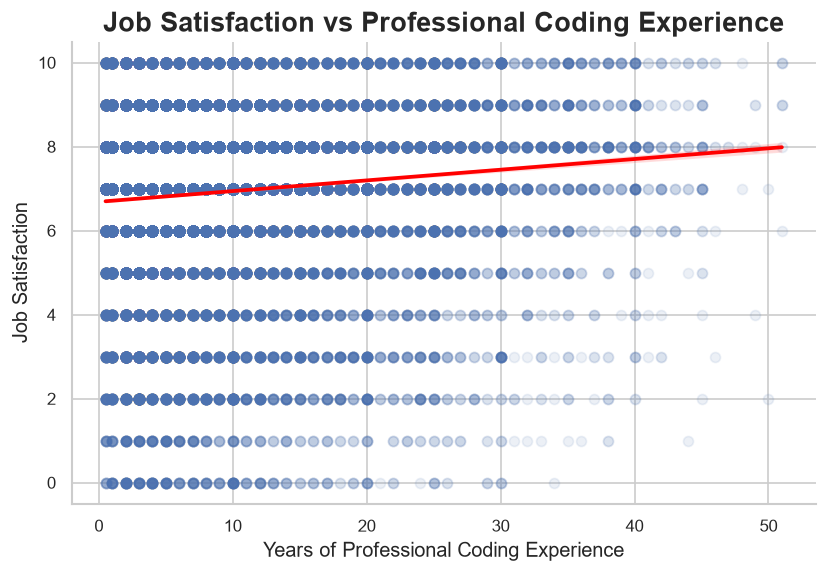

In [106]:
# Plot a scatterplot with a regression line
sns.regplot(
    data=df,
    x='YearsCodePro',
    y='JobSat',
    scatter_kws={'alpha': 0.1},
    line_kws={'color': 'red'}
)

plt.title('Job Satisfaction vs Professional Coding Experience')
plt.xlabel('Years of Professional Coding Experience')
plt.ylabel('Job Satisfaction')

plt.show()

Although average job satisfaction increases as professional coding experience increases, and there is indeed a weak positive correlation, the correlation results suggest that professional coding experience is not a particularly strong predictor of job satisfaction.

We can investigate the distribution of job satisfaction using a bar chart.

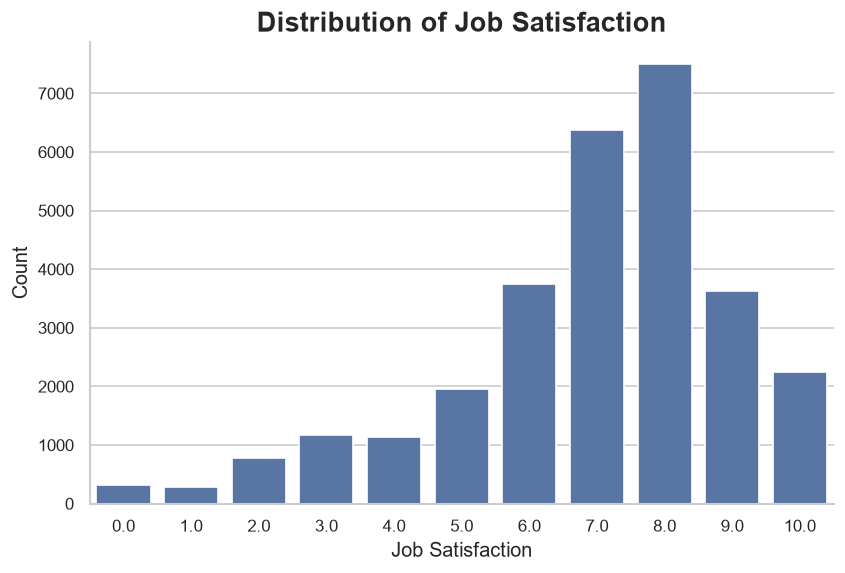

In [100]:
# Plot a countplot
sns.countplot(data = df, x = 'JobSat')

plt.title('Distribution of Job Satisfaction')
plt.xlabel('Job Satisfaction')
plt.ylabel('Count')

plt.show()

A job satisfaction of 8/10 seems to be the most common value, with higher and lower values being less common.

## 4.4 Remote Work Preferences

We can also use a bar chart to investigate the distribution of remote work preferences.

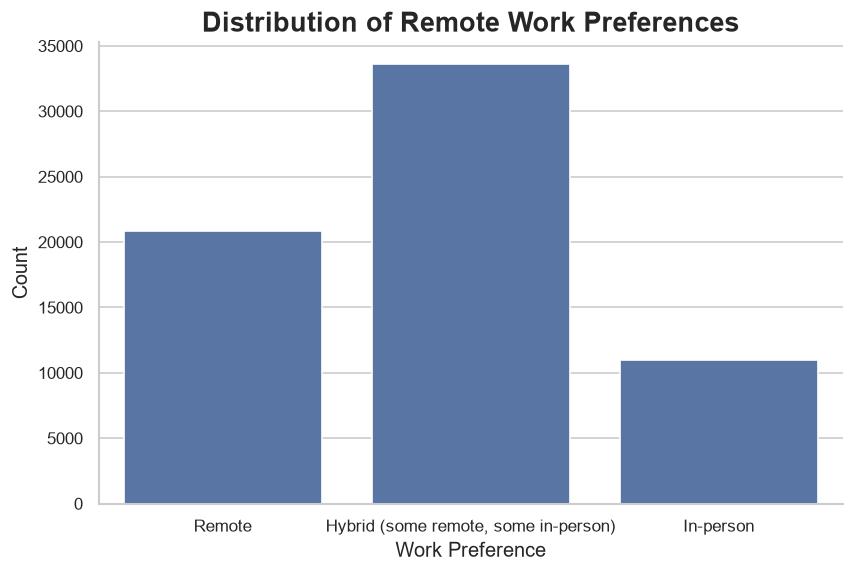

In [101]:
# Plot a countplot
sns.countplot(data = df, x = 'RemoteWork')

plt.title('Distribution of Remote Work Preferences')
plt.xlabel('Work Preference')
plt.ylabel('Count')

plt.show()

Hybrid work (some remote, some in-person) appears to be the most popular form of work, with remote work in close second. In-person work is the least popular.

We can also investigate how this trend differs by country.

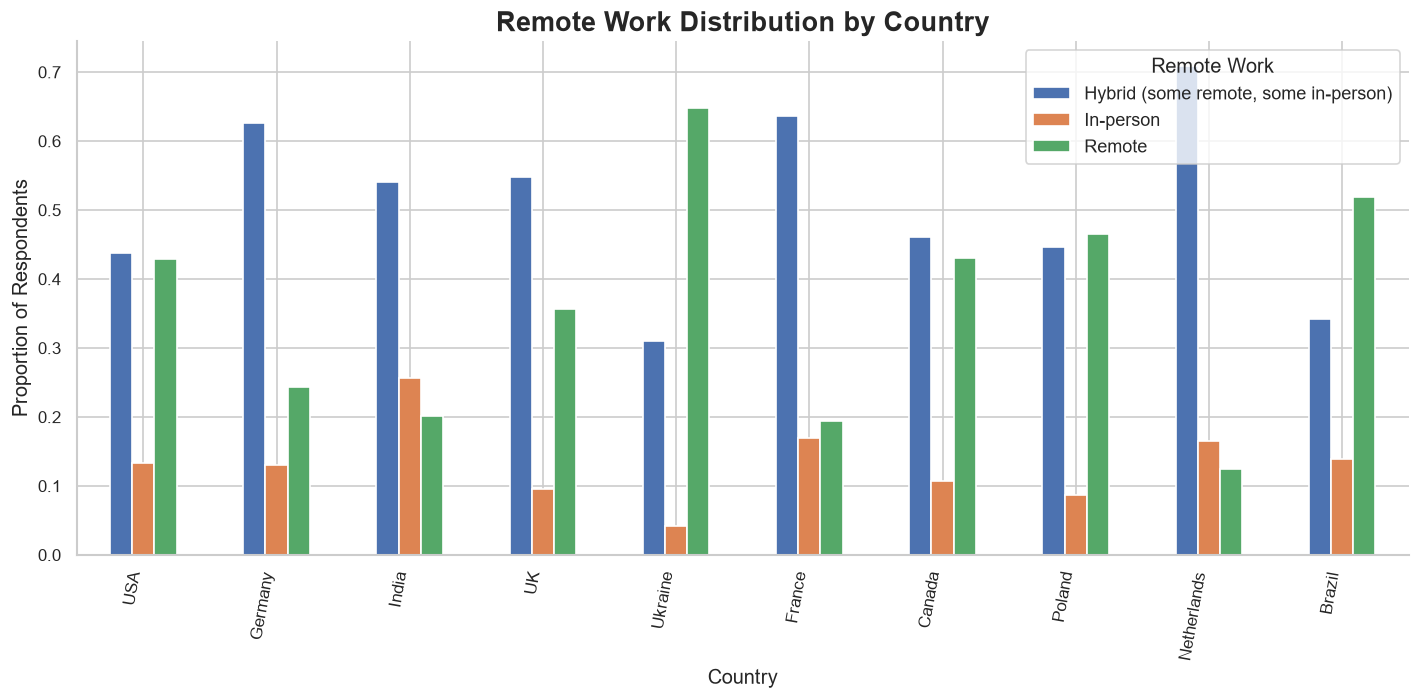

In [102]:
# Identify the 10 countries with the most respondents
top_countries = df['Country'].value_counts().head(10).index

#Create a cross-tabulation of remote work by country
remote_region = pd.crosstab(df['Country'], df['RemoteWork'], normalize = 'index')

# Filter to the top 10 countries
remote_region = remote_region.loc[top_countries]
remote_region = remote_region.rename(index = {
    'United States of America': 'USA',
    'United Kingdom of Great Britain and Northern Ireland': 'UK'
})

# Plot
remote_region.plot(kind = 'bar', figsize = (12, 6))

plt.title('Remote Work Distribution by Country')
plt.xlabel('Country')
plt.ylabel('Proportion of Respondents')
plt.legend(title = 'Remote Work')
plt.xticks(rotation = 80, ha = 'right')
plt.tight_layout()
plt.show()

The trend in remote work preferences differs greatly by country. The USA is the most common country, so the overall trend largely fits with the trend in the USA.

## 4.5 Programming Language and Industry Preference

We can investigate the programming languages that respondents have worked with and want to work with.

In [88]:
languages = (df['LanguageHaveWorkedWith'].dropna().str.split(';').explode())
print(languages.value_counts().head(10))

LanguageHaveWorkedWith
JavaScript                 37492
HTML/CSS                   31816
Python                     30719
SQL                        30682
TypeScript                 23150
Bash/Shell (all shells)    20412
Java                       18239
C#                         16318
C++                        13827
C                          12184
Name: count, dtype: int64


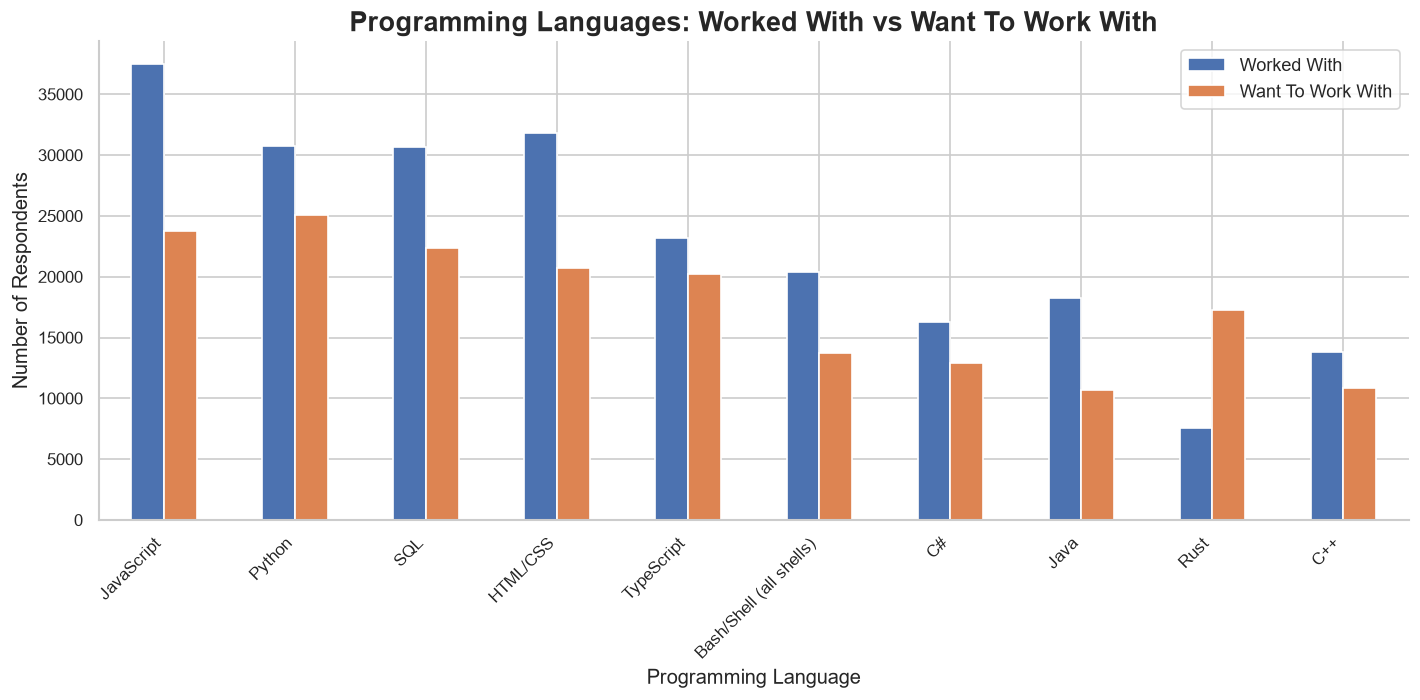

In [89]:
from collections import Counter

# Initialise counters
worked = Counter()
wanted = Counter()

# Calculate languages respondents have worked with
for langs in df['LanguageHaveWorkedWith'].dropna():
    worked.update(lang.strip() for lang in langs.split(';'))

# Calculate languages respondents want to work with
for langs in df['LanguageWantToWorkWith'].dropna():
    wanted.update(lang.strip() for lang in langs.split(';'))

# Create a DataFrame for language counts
language_counts = pd.DataFrame({'Worked With' : pd.Series(worked), 'Want To Work With' : pd.Series(wanted)}).fillna(0)

# Calculate top 10 languages
top_languages = language_counts.sum(axis = 1).sort_values(ascending = False).head(10).index

# Plot
language_counts.loc[top_languages].plot(kind = 'bar', figsize = (12, 6))

plt.title('Programming Languages: Worked With vs Want To Work With')
plt.xlabel('Programming Language')
plt.ylabel('Number of Respondents')
plt.xticks(rotation = 45, ha = 'right')

plt.tight_layout()
plt.show()

JavaScript is the most common language that respondents have worked with. It also appears to be among the most popular languages that respondents want to work with, though it is just edged out of first place by Python in this regard. 

We can investigate the top industries among survey respondents.

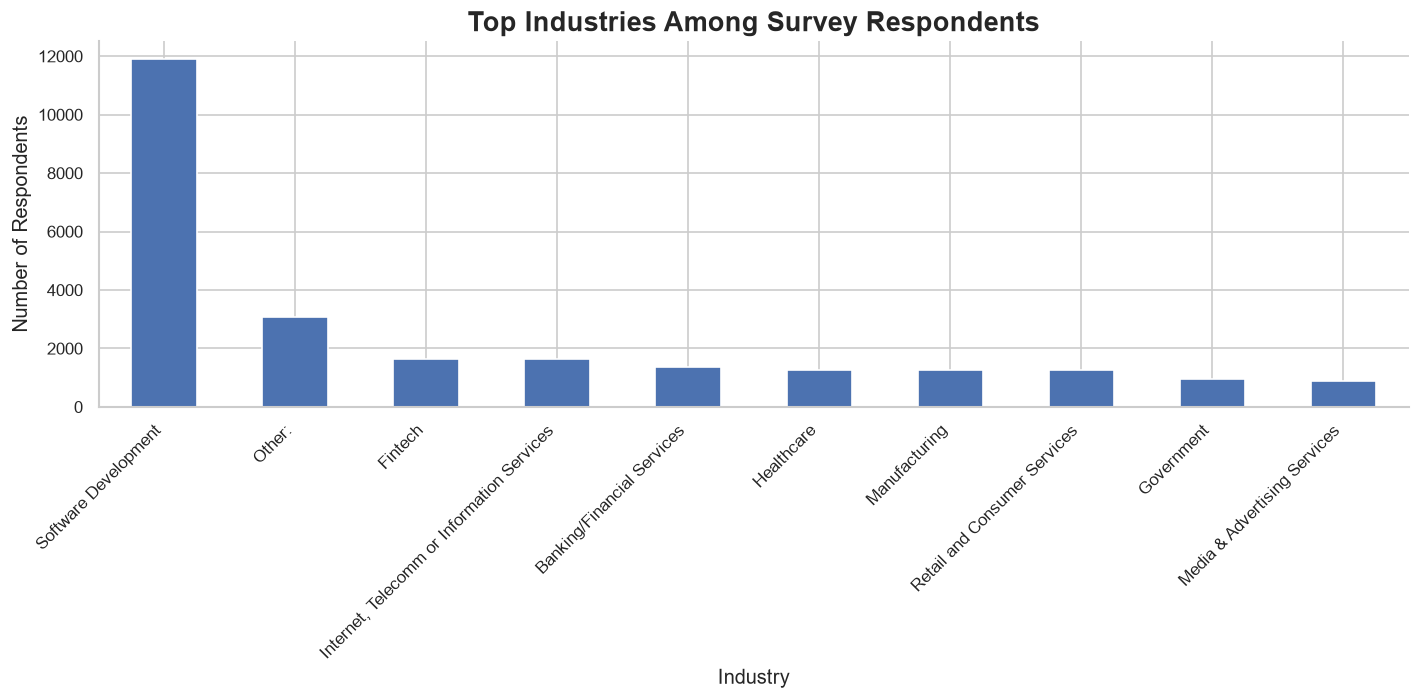

In [104]:
# Calculate top 10 industries among respondents
industry_counts = df['Industry'].value_counts()
top_industries = industry_counts.head(10)

# Plot
plt.figure(figsize=(12,6))
top_industries.plot(kind='bar')

plt.title('Top Industries Among Survey Respondents')
plt.xlabel('Industry')
plt.ylabel('Number of Respondents')
plt.xticks(rotation = 45, ha = 'right')
plt.tight_layout()
plt.show()

By some margin, the top industry among survey respondents was software development.

# 5. Key Findings

1. **The most commonly used programming languages.**
   - JavaScript was the top programming language used among respondents.
2. **The most popular languages developers want to learn.**
   - JavaScript, Python, and SQL were the top languages respondents wanted to learn, with Python being the most popular.
3. **The distribution of remote working arrangements.**
   - Hybrid work (part remote, part in-person) was the most common among respondents, with in-person work being the least common.
   - This trend was not consistent among different countries.
4. **The relationship between professional experience and job satisfaction.**
   - Job satisfaction appeared to increase as experience increased, showing a weak positive correlation.
   - This relationship was not strong enough to make experience a reliable predictor of job satisfaction.
5. **Top industries among respondents.**
   - Software development was found to be the top industry among survey respondents.
6. **Differences in compensation across countries.**
   - The USA was found to provide the highest mean annual compensation among the top 10 most common countries in the survey.

# 6. Conclusion

We have analysed the Stack Overflow Developer Survey and gained some insight into the data. However, it is important to acknowledge limitations of these analyses. These limitations include:
- Survey responses are self-reported.
- Survey respondents represent a small subset of the developer community rather than the entire population.
- Missing salary information limits compensation analysis.
- Correlations do not establish causation.